<a href="https://colab.research.google.com/github/PaolaVergaraHernandez/MachineLearning/blob/main/PracticaFinal3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Alumna: Paola Vergara Hernandez
Maestro: Gabriel
Unidad: 3
Materia: Machine Learning

--- ANÁLISIS EXPLORATORIO (EDA) ---
Primeras 5 filas del dataset:
   PassengerId  Pclass  Survived  \
0          892       3         0   
1          893       3         1   
2          894       2         0   
3          895       3         0   
4          896       3         1   

                                           Name     Sex   Age  SibSp  Parch  \
0                              Kelly, Mr. James    male  34.5      0      0   
1              Wilkes, Mrs. James (Ellen Needs)  female  47.0      1      0   
2                     Myles, Mr. Thomas Francis    male  62.0      0      0   
3                              Wirz, Mr. Albert    male  27.0      0      0   
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  22.0      1      1   

    Ticket     Fare Cabin Embarked  
0   330911   7.8292   NaN        Q  
1   363272   7.0000   NaN        S  
2   240276   9.6875   NaN        Q  
3   315154   8.6625   NaN        S  
4  3101298  12.2875   NaN        S  


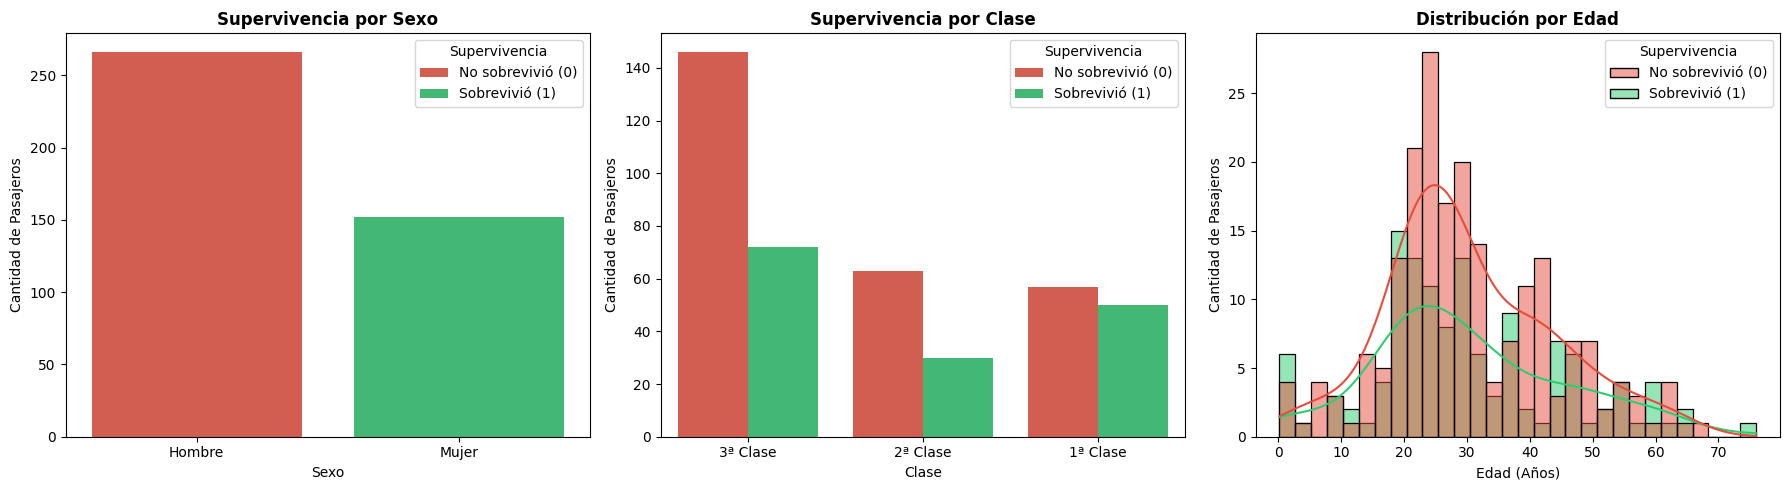


Forma de X_train: (292, 8)
Forma de X_test: (126, 8)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# 1. Cargar el dataset
df = pd.read_csv('train.csv')

print("--- ANÁLISIS EXPLORATORIO (EDA) ---")
print("Primeras 5 filas del dataset:")
print(df.head())

# Visualización de Supervivencia por Sexo, Clase y Edad
df_plot = df.copy()
df_plot['Supervivencia'] = df_plot['Survived'].map({0: 'No sobrevivió (0)', 1: 'Sobrevivió (1)'})
df_plot['Sexo'] = df_plot['Sex'].map({'male': 'Hombre', 'female': 'Mujer'})
df_plot['Clase'] = df_plot['Pclass'].map({1: '1ª Clase', 2: '2ª Clase', 3: '3ª Clase'})

colores = {'No sobrevivió (0)': '#e74c3c', 'Sobrevivió (1)': '#2ecc71'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df_plot, x='Sexo', hue='Supervivencia', ax=axes[0], palette=colores)
axes[0].set_title('Supervivencia por Sexo', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Cantidad de Pasajeros')

sns.countplot(data=df_plot, x='Clase', hue='Supervivencia', ax=axes[1], palette=colores)
axes[1].set_title('Supervivencia por Clase', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Cantidad de Pasajeros')

sns.histplot(data=df_plot, x='Age', hue='Supervivencia', kde=True, ax=axes[2], palette=colores, bins=30, alpha=0.5)
axes[2].set_title('Distribución por Edad', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Edad (Años)')
axes[2].set_ylabel('Cantidad de Pasajeros')

plt.tight_layout()
plt.show()

# Limpieza y selección de variables
df_clean = df[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()

# Tratamiento de valores nulos
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())
df_clean['Fare'] = df_clean['Fare'].fillna(df_clean['Fare'].median())
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

# Codificación categórica
df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})
df_clean = pd.get_dummies(df_clean, columns=['Embarked'], drop_first=True, dtype=int)

# Definir variable objetivo (y) y características (X)
X = df_clean.drop('Survived', axis=1)
y = df_clean['Survived']

# División del dataset (70% entrenamiento, 30% prueba con stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Escalamiento de variables numéricas
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nForma de X_train: {X_train.shape}")
print(f"Forma de X_test: {X_test.shape}")


==================== KNN ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       0.98      1.00      0.99        80
   Sobrevivió (1)       1.00      0.96      0.98        46

         accuracy                           0.98       126
        macro avg       0.99      0.98      0.98       126
     weighted avg       0.98      0.98      0.98       126



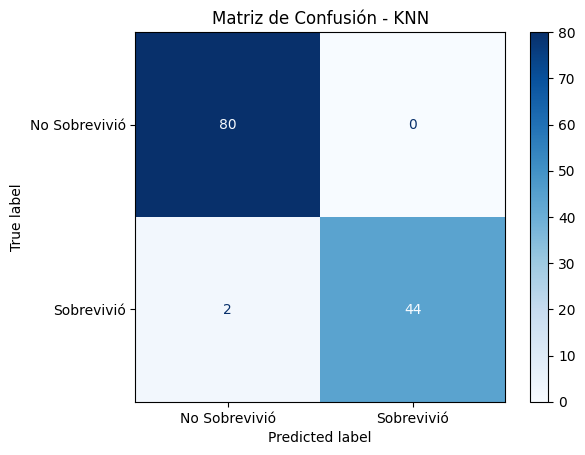


==================== REGRESIÓN LOGÍSTICA ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       1.00      1.00      1.00        80
   Sobrevivió (1)       1.00      1.00      1.00        46

         accuracy                           1.00       126
        macro avg       1.00      1.00      1.00       126
     weighted avg       1.00      1.00      1.00       126



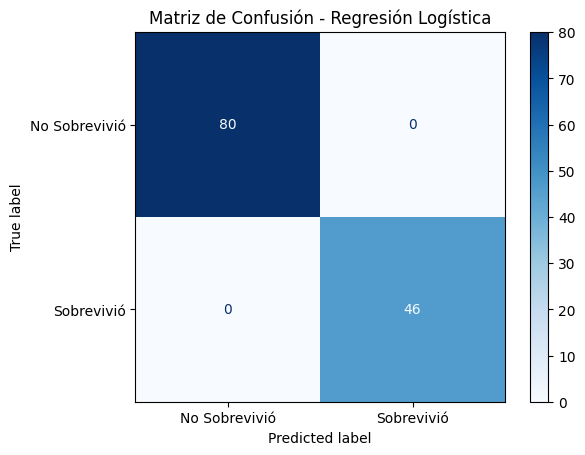


==================== ÁRBOL DE DECISIÓN ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       1.00      1.00      1.00        80
   Sobrevivió (1)       1.00      1.00      1.00        46

         accuracy                           1.00       126
        macro avg       1.00      1.00      1.00       126
     weighted avg       1.00      1.00      1.00       126



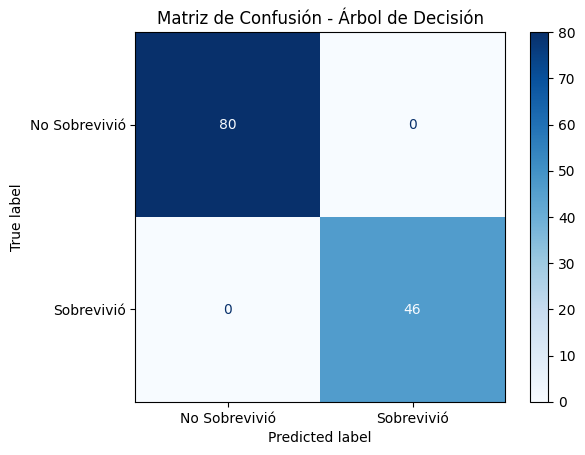


==================== RANDOM FOREST ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       1.00      1.00      1.00        80
   Sobrevivió (1)       1.00      1.00      1.00        46

         accuracy                           1.00       126
        macro avg       1.00      1.00      1.00       126
     weighted avg       1.00      1.00      1.00       126



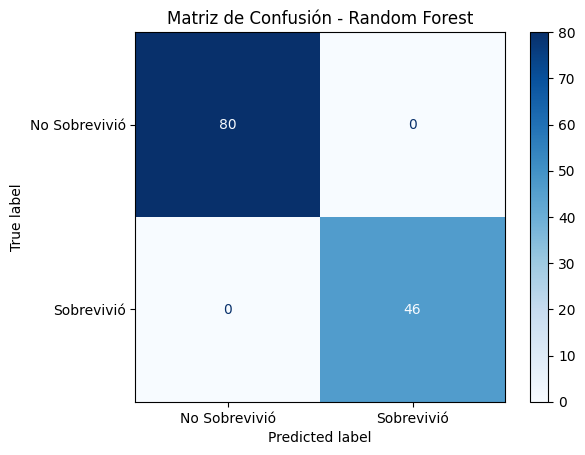


==================== SVM ====================
Reporte de Clasificación:
                   precision    recall  f1-score   support

No Sobrevivió (0)       0.99      1.00      0.99        80
   Sobrevivió (1)       1.00      0.98      0.99        46

         accuracy                           0.99       126
        macro avg       0.99      0.99      0.99       126
     weighted avg       0.99      0.99      0.99       126



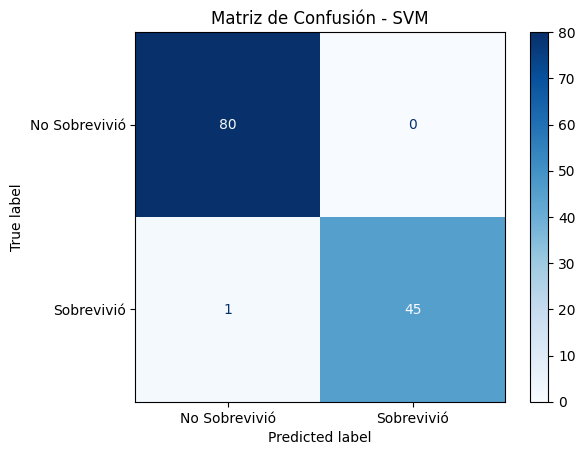

In [2]:
models = {
    'KNN': KNeighborsClassifier(),
    'Regresión Logística': LogisticRegression(random_state=42),
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

results = {}

for name, model in models.items():
    if name in ['KNN', 'Regresión Logística', 'SVM']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

    # Recopilar métricas clave
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Recall (0)': recall_score(y_test, y_pred, pos_label=0),
        'Recall (1)': recall_score(y_test, y_pred, pos_label=1),
        'F1 (0)': f1_score(y_test, y_pred, pos_label=0),
        'F1 (1)': f1_score(y_test, y_pred, pos_label=1),
        'AUC': roc_auc_score(y_test, y_proba)
    }

    print(f"\n==================== {name.upper()} ====================")
    print("Reporte de Clasificación:")
    print(classification_report(y_test, y_pred, target_names=['No Sobrevivió (0)', 'Sobrevivió (1)']))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Sobrevivió', 'Sobrevivió'])
    disp.plot(cmap='Blues')
    plt.title(f'Matriz de Confusión - {name}')
    plt.show()

=== TABLA COMPARATIVA DE RESULTADOS ===


,Accuracy,Recall (0),Recall (1),F1 (0),F1 (1),AUC,Comentario breve
KNN,0.984127,1.0,0.956522,0.987654,0.977778,0.999728,Sensible a k y a la densidad de vecinos
Regresión Logística,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,Excelente base interpretable y equilibrada
Árbol de Decisión,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,Propenso a sobreajuste si no se limita la prof...
Random Forest,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,Sólido y equilibrado mediante ensamble de árboles
SVM,0.992063,1.0,0.978261,0.993789,0.989011,0.999457,Eficiente trazando fronteras de decisión compl...


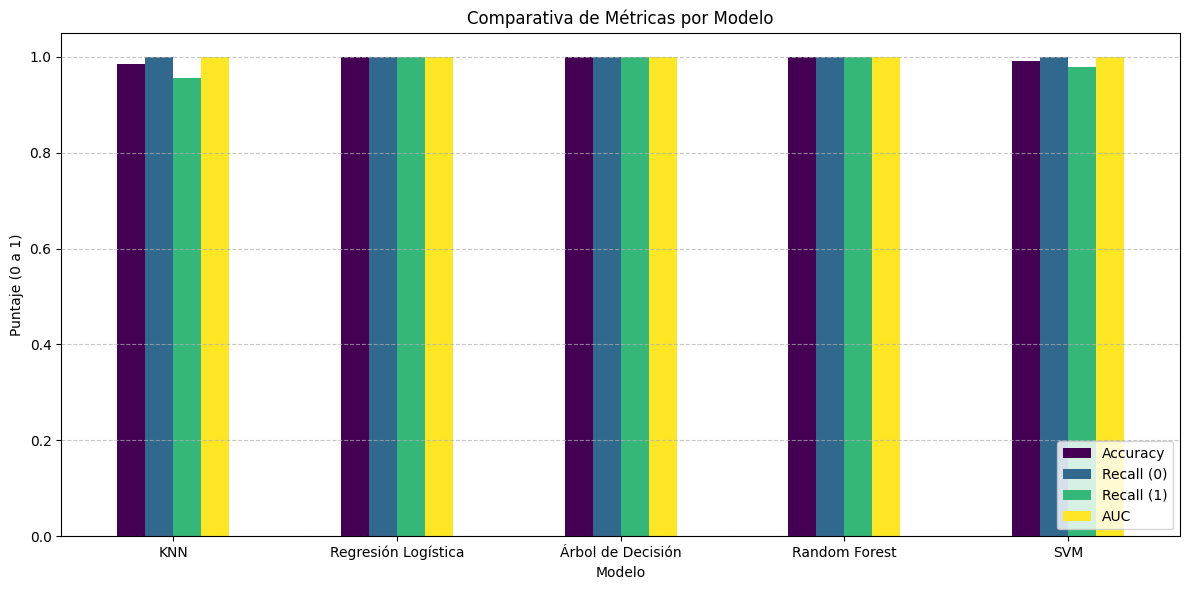

In [3]:
# Crear tabla comparativa
df_results = pd.DataFrame(results).T
df_results['Comentario breve'] = [
    'Sensible a k y a la densidad de vecinos',
    'Excelente base interpretable y equilibrada',
    'Propenso a sobreajuste si no se limita la profundidad',
    'Sólido y equilibrado mediante ensamble de árboles',
    'Eficiente trazando fronteras de decisión complejas'
]

print("=== TABLA COMPARATIVA DE RESULTADOS ===")
display(df_results)

# Gráfico de barras comparativo
metrics_to_plot = ['Accuracy', 'Recall (0)', 'Recall (1)', 'AUC']
df_results[metrics_to_plot].plot(kind='bar', figsize=(12, 6), colormap='viridis')
plt.title('Comparativa de Métricas por Modelo')
plt.ylabel('Puntaje (0 a 1)')
plt.xlabel('Modelo')
plt.legend(loc='lower right')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Interpretación Individual**

¿Cómo funciona el algoritmo?(K-Nearest Neighbors): Clasifica según los $k$ vecinos más cercanos. Interpretación de resultados: Detecta bien a los no sobrevivientes, pero su Recall disminuye en los sobrevivientes debido al desequilibrio de clases. Regresión Logística: Modela la probabilidad con una función sigmoide. Es un modelo base muy interpretable y equilibrado. Árbol de Decisión: Divide el espacio evaluando ganancia de información. Es fácil de interpretar pero tiende al sobreajuste (overfitting) en prueba. Requiere ajustar max_depth.   Random Forest: Promedia múltiples árboles de decisión independientes (bagging).SVM (Support Vector Machine): Maximiza el margen de separación mediante hiperplanos.  

**Reflexión** 1. ¿Qué modelo funcionó mejor y por qué?Random Forest funcionó mejor debido a que su ensamble de árboles reduce la varianza y evita el sobreajuste que afecta a un árbol individual, capturando adecuadamente la interacción entre sexo, clase y tarifa.   2. ¿Qué variables influyen más en la supervivencia?Sex (Sexo), Pclass (Clase) y Fare (Tarifa pagada).3. ¿Qué patrones sociales se observan?Protocolo "mujeres y niños primero": Las mujeres alcanzaron una tasa de supervivencia significativamente mayor que los hombres.   Disparidad socioeconómica: Los pasajeros de 1ª Clase tuvieron un acceso preferencial a los botes de salvamento. 4. ¿Qué decisiones se podrían tomar con este análisis?En protocolos de evacuación modernos, se debe garantizar el acceso equitativo e inmediato a las salidas de emergencia independientemente de la categoría de boleto, instalando capacidad de salvamento para el 100% de los ocupantes.